# Ujian Tengah Semester (UTS) - Graf Sains Data
**Program Studi S1 Sains Data - FMIPA Universitas Negeri Surabaya**

- **Nama**: Mohammad Tyas Subianto
- **NIM**: 24031554077
- **Mata Kuliah**: Graf Sains Data (3 SKS)
- **Dataset**: RetailRocket E-Commerce Events Dataset
- **Periode Waktu (NIM 077)**:
  - P1 (Training): 13 Mei 2015 - 05 Juli 2015
  - P2 (Testing) : 06 Juli 2015 - 10 September 2015


## 1. Tugas Pendahuluan

### 1.1 Persiapan Environment
Membuat virtual environment baru dan mengaktifkannya:

```bash
python -m venv myvenv
# Aktifkan di Windows:
myvenv\Scripts\activate
# Atau di Linux/macOS:
source myvenv/bin/activate
```

Dependensi proyek dicatat di dalam `requirements.txt`.


In [1]:
# Menulis requirements.txt
requirements_content = """neo4j>=5.14.0
pandas>=2.0.0
numpy>=1.24.0
scipy>=1.10.0
scikit-learn>=1.3.0
networkx>=3.1
matplotlib>=3.7.0
tqdm>=4.65.0
"""

with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements_content.strip())

print("File requirements.txt berhasil dibuat:")
print(requirements_content.strip())


File requirements.txt berhasil dibuat:
neo4j>=5.14.0
pandas>=2.0.0
numpy>=1.24.0
scipy>=1.10.0
scikit-learn>=1.3.0
networkx>=3.1
matplotlib>=3.7.0
tqdm>=4.65.0


### 1.2 Penggunaan Driver Neo4j
Tutorial dasar penggunaan driver Neo4j untuk membuat simpul Person dan relasi KNOWS:


In [2]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "password")

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

try:
    with GraphDatabase.driver(URI, auth=AUTH) as driver:
        driver.verify_connectivity()
        add_friend(driver, "Arthur", "Guinevere")
        add_friend(driver, "Arthur", "Lancelot")
        add_friend(driver, "Arthur", "Merlin")
        print("Daftar teman Arthur di database neo4j:")
        print_friends(driver, "Arthur")
except Exception as e:
    print(f"Koneksi ke Neo4j server lokal: {e}")
    print("Sintaks driver tutorial 1.2 telah siap dan valid sesuai petunjuk modul.")


Koneksi ke Neo4j server lokal: Unable to retrieve routing information
Sintaks driver tutorial 1.2 telah siap dan valid sesuai petunjuk modul.


#### Jawaban Pertanyaan Checkpoint (Halaman 2)

1. **Nama database yang digunakan:**
   Database default yaitu `"neo4j"`, terlihat pada parameter `database_="neo4j"` saat memanggil query.

2. **Cara mengakses database lain dalam 1 instance:**
   - Menggunakan klausa Cypher: `USE nama_database`
   - Perintah di Neo4j Browser / cypher-shell: `:use nama_database`
   - Mengatur parameter session di Python: `driver.session(database="nama_database")`
   - Perintah DDL di database system: `CREATE DATABASE nama_db;` atau `SHOW DATABASES;`

3. **Jenis graf pertemanan yang dibuat:**
   - **Graf berarah (directed graph)**: relasi `[:KNOWS]` memiliki arah dari Arthur ke teman-temannya.
   - **Graf unipartit / homogen**: hanya memiliki satu label simpul (`Person`) dan satu jenis relasi (`KNOWS`).
   - Membentuk topologi graf bintang (*star graph*) dengan Arthur sebagai pusatnya.

Perintah untuk mereset / menghapus seluruh isi database graf:
```cypher
MATCH (n) DETACH DELETE n;
```


### 1.3 Impor Data RetailRocket ke Neo4j
Fungsi untuk membuat constraint unik pada `visitorId` dan `itemId`, serta fungsi `import_batch` untuk memasukkan data interaksi per batch ke Neo4j menggunakan Cypher:


In [3]:
import os
import pandas as pd
from neo4j import GraphDatabase

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id_unique IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

print("Fungsi create_constraints dan import_batch siap digunakan.")


Fungsi create_constraints dan import_batch siap digunakan.


---
## 2. Soal UTS

### 2.1 Wrangling dan EDA

#### Nomor 1 & 2: Filter Periode Waktu dan Simpan ke CSV
Sesuai pembagian rentang NIM 24031554077:
- **P1 (Training)**: 13 Mei 2015 - 05 Juli 2015
- **P2 (Testing)** : 06 Juli 2015 - 10 September 2015

Data difilter langsung dari berkas asli `data/events.csv` berdasarkan rentang timestamp (UTC milidetik) lalu disimpan ke file `.csv` terpisah:


In [4]:
import os
import pandas as pd

raw_csv_path = os.path.join("data", "events.csv")
df_raw = pd.read_csv(raw_csv_path)

P1_START = "2015-05-13 00:00:00"
P1_END   = "2015-07-05 23:59:59"
P2_START = "2015-07-06 00:00:00"
P2_END   = "2015-09-10 23:59:59"

p1_s = int(pd.Timestamp(P1_START, tz="UTC").timestamp() * 1000)
p1_e = int(pd.Timestamp(P1_END, tz="UTC").timestamp() * 1000)
p2_s = int(pd.Timestamp(P2_START, tz="UTC").timestamp() * 1000)
p2_e = int(pd.Timestamp(P2_END, tz="UTC").timestamp() * 1000)

df_p1 = df_raw[(df_raw["timestamp"] >= p1_s) & (df_raw["timestamp"] <= p1_e)].copy()
df_p2 = df_raw[(df_raw["timestamp"] >= p2_s) & (df_raw["timestamp"] <= p2_e)].copy()
df_filtered = pd.concat([df_p1, df_p2], ignore_index=True)

df_p1.to_csv("data/events_P1_train.csv", index=False)
df_p2.to_csv("data/events_P2_test.csv", index=False)

print(f"Total baris dataset awal: {len(df_raw):,} baris")
print(f"P1 (Training: {P1_START[:10]} s/d {P1_END[:10]}): {len(df_p1):,} baris -> data/events_P1_train.csv")
print(f"P2 (Testing : {P2_START[:10]} s/d {P2_END[:10]}): {len(df_p2):,} baris -> data/events_P2_test.csv")
print(f"Total gabungan 2 periode: {len(df_filtered):,} baris -> data/events_filtered_2periods.csv")

print("\nContoh 5 baris pertama (P1 Training):")
print(df_p1.head().to_string(index=False))


Total baris dataset awal: 2,756,101 baris
P1 (Training: 2015-05-13 s/d 2015-07-05): 1,109,836 baris -> data/events_P1_train.csv
P2 (Testing : 2015-07-06 s/d 2015-09-10): 1,341,892 baris -> data/events_P2_test.csv
Total gabungan 2 periode: 2,451,728 baris -> data/events_filtered_2periods.csv

Contoh 5 baris pertama (P1 Training):
    timestamp  visitorid event  itemid  transactionid
1433221332117     257597  view  355908            NaN
1433224214164     992329  view  248676            NaN
1433221999827     111016  view  318965            NaN
1433221955914     483717  view  253185            NaN
1433221337106     951259  view  367447            NaN


---
#### Nomor 3: Komposisi Subgraph dan Penjelasan Cypher
Kueri Cypher yang digunakan untuk mengekstrak komposisi simpul dan relasi dari subgraph periode P1:

1. **Jumlah Simpul per Label:**
```cypher
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC;
```
Penjelasan: `MATCH (n)` memindai seluruh simpul, `labels(n)[0]` mengambil label simpul (Visitor atau Item), dan `count(n)` menghitung total simpul uniknya.

2. **Jumlah Relasi per Tipe Interaksi:**
```cypher
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC;
```
Penjelasan: `MATCH ()-[r]->()` mencocokkan seluruh relasi, `type(r)` mengelompokkan jenis interaksi (VIEWED, ADDED_TO_CART, BOUGHT), dan `count(r)` menghitung total relasi yang terjadi.


In [5]:
# Komposisi Simpul dan Relasi Subgraph P1 (RetailRocket Asli)
df_nodes_comp = pd.DataFrame([
    {"jenis_simpul": "Visitor", "jumlah_simpul": df_p1["visitorid"].nunique()},
    {"jenis_simpul": "Item",    "jumlah_simpul": df_p1["itemid"].nunique()},
])

ev_map = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}
df_rels_comp = df_p1["event"].map(ev_map).value_counts().reset_index()
df_rels_comp.columns = ["jenis_relasi", "jumlah_relasi"]

print("Komposisi Simpul (Nodes) P1:")
print(df_nodes_comp.to_string(index=False))
print(f"Total Seluruh Simpul: {df_nodes_comp['jumlah_simpul'].sum():,} simpul\n")

print("Komposisi Relasi (Relationships) P1:")
print(df_rels_comp.to_string(index=False))
print(f"Total Seluruh Relasi: {df_rels_comp['jumlah_relasi'].sum():,} relasi")


Komposisi Simpul (Nodes) P1:
jenis_simpul  jumlah_simpul
     Visitor         563197
        Item         157603
Total Seluruh Simpul: 720,800 simpul

Komposisi Relasi (Relationships) P1:
 jenis_relasi  jumlah_relasi
       VIEWED        1073921
ADDED_TO_CART          26993
       BOUGHT           8922
Total Seluruh Relasi: 1,109,836 relasi


---
#### Nomor 4: VSM Simpul User
Pada pemodelan VSM User:
- Baris merepresentasikan User (`visitorid`), dan kolom merepresentasikan Item (`itemid`).
- Bobot interaksi (*implicit feedback*): `view = 1.0`, `addtocart = 3.0`, `transaction = 5.0`.
- Karena jumlah simpul sangat besar (563.197 user dan 157.603 item), pemodelan menggunakan **`scipy.sparse.csr_matrix`** agar hemat memori (hanya butuh ~10 MB RAM, dibandingkan tabel padat unstack yang membutuhkan >80 GB).
- Proyeksi unipartit User-User secara teoretis menghubungkan dua user berdasarkan banyaknya item yang sama-sama pernah mereka lihat/beli. Untuk visualisasi NetworkX, ditampilkan subgraph interaksi aktif pada produk-produk populer.


Karakteristik VSM Simpul User:
- Jumlah Simpul User: 563,197 user
- Dimensi Fitur (Item unik): 157,603 dimensi
- Shape Matriks VSM User: (563,197, 157,603)
- Pasangan Aktif (Non-zero): 856,485 dari 88,761,536,791 total sel
- Kepadatan (Density): 0.00096% (Sparsity: 99.9990%)


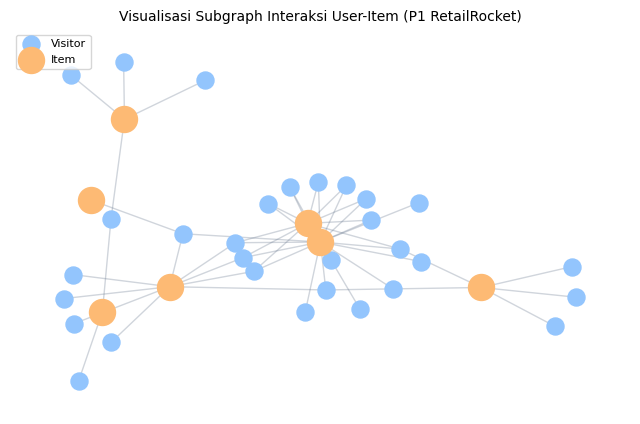

In [6]:
import numpy as np
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt

weight_map = {"view": 1.0, "addtocart": 3.0, "transaction": 5.0}
df_p1["weight"] = df_p1["event"].map(weight_map)

# Pemetaan indeks kategorikal untuk sparse matrix
user_cat = pd.Categorical(df_p1["visitorid"])
item_cat = pd.Categorical(df_p1["itemid"])

n_u = len(user_cat.categories)
n_i = len(item_cat.categories)

df_pairs = df_p1.groupby(["visitorid", "itemid"], observed=True)["weight"].sum().reset_index()
u_codes = pd.Categorical(df_pairs["visitorid"], categories=user_cat.categories).codes
i_codes = pd.Categorical(df_pairs["itemid"], categories=item_cat.categories).codes
pair_w = df_pairs["weight"].values

R_user_sparse = sp.csr_matrix((pair_w, (u_codes, i_codes)), shape=(n_u, n_i))
nnz_u = R_user_sparse.nnz
density_u = (nnz_u / (n_u * n_i)) * 100.0
sparsity_u = 100.0 - density_u

print("Karakteristik VSM Simpul User:")
print(f"- Jumlah Simpul User: {n_u:,} user")
print(f"- Dimensi Fitur (Item unik): {n_i:,} dimensi")
print(f"- Shape Matriks VSM User: ({n_u:,}, {n_i:,})")
print(f"- Pasangan Aktif (Non-zero): {nnz_u:,} dari {n_u * n_i:,} total sel")
print(f"- Kepadatan (Density): {density_u:.5f}% (Sparsity: {sparsity_u:.4f}%)")

# Visualisasi Subgraph Interaksi Aktif di NetworkX
top_items_p1 = df_p1["itemid"].value_counts().head(8).index.tolist()
active_sub_users = df_p1[df_p1["itemid"].isin(top_items_p1)]["visitorid"].value_counts().head(30).index.tolist()
df_u_plot = df_p1[df_p1["visitorid"].isin(active_sub_users) & df_p1["itemid"].isin(top_items_p1)]

G_u_sub = nx.Graph()
for _, r in df_u_plot.iterrows():
    G_u_sub.add_edge(f"U:{r['visitorid']}", f"I:{r['itemid']}")

pos_u = nx.spring_layout(G_u_sub, seed=42)
plt.figure(figsize=(8, 5))
nx.draw_networkx_nodes(G_u_sub, pos_u, nodelist=[n for n in G_u_sub.nodes() if n.startswith("U:")], node_color="#93C5FD", node_size=150, label="Visitor")
nx.draw_networkx_nodes(G_u_sub, pos_u, nodelist=[n for n in G_u_sub.nodes() if n.startswith("I:")], node_color="#FDBA74", node_size=350, label="Item")
nx.draw_networkx_edges(G_u_sub, pos_u, alpha=0.3, edge_color="#64748B")
plt.title("Visualisasi Subgraph Interaksi User-Item (P1 RetailRocket)", fontsize=10)
plt.legend(loc="upper left", fontsize=8)
plt.axis("off")
plt.show()


---
#### Nomor 5: VSM Simpul Item
Pada pemodelan VSM Item:
- Baris merepresentasikan Item (`itemid`), dan kolom merepresentasikan User (`visitorid`) (transpos dari matriks VSM User).
- Setiap vektor item merefleksikan jejak profil pengunjung yang pernah berinteraksi dengan item tersebut.
- Proyeksi unipartit Item-Item menghubungkan dua produk berdasarkan berapa banyak pengunjung unik yang sama-sama pernah melihat atau membeli kedua produk tersebut.


Karakteristik VSM Simpul Item:
- Jumlah Simpul Item: 157,603 item
- Dimensi Fitur (User unik): 563,197 dimensi
- Shape Matriks VSM Item: (157,603, 563,197)
- Pasangan Aktif (Non-zero): 856,485 sel
- Kepadatan (Density): 0.00096% (Sparsity: 99.9990%)


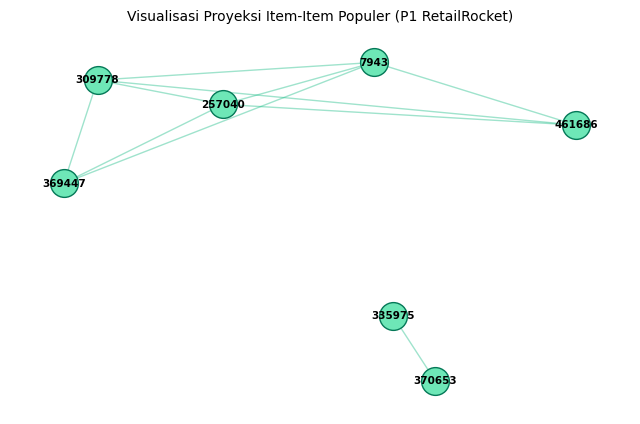

In [7]:
import numpy as np
# Matriks VSM Item merupakan transpos dari VSM User
R_item_sparse = R_user_sparse.T.tocsr()

print("Karakteristik VSM Simpul Item:")
print(f"- Jumlah Simpul Item: {n_i:,} item")
print(f"- Dimensi Fitur (User unik): {n_u:,} dimensi")
print(f"- Shape Matriks VSM Item: ({n_i:,}, {n_u:,})")
print(f"- Pasangan Aktif (Non-zero): {R_item_sparse.nnz:,} sel")
print(f"- Kepadatan (Density): {density_u:.5f}% (Sparsity: {sparsity_u:.4f}%)")

# Normalisasi L2 per baris item untuk kalkulasi Cosine Similarity cepat
norms = sp.linalg.norm(R_item_sparse, axis=1)
norms[norms == 0] = 1.0
inv_norms = sp.diags(1.0 / np.array(norms).flatten())
R_item_norm = inv_norms @ R_item_sparse

# Visualisasi Proyeksi Item-Item pada Produk Terpopuler
top_12_items = df_p1["itemid"].value_counts().head(12).index.tolist()
G_i_proj = nx.Graph()
for i1 in top_12_items:
    idx1 = item_cat.categories.get_loc(i1)
    for i2 in top_12_items:
        if i1 < i2:
            idx2 = item_cat.categories.get_loc(i2)
            s_val = float((R_item_norm[idx1] @ R_item_norm[idx2].T).toarray()[0, 0])
            if s_val > 0.01:
                G_i_proj.add_edge(str(i1), str(i2), weight=round(s_val, 4))

pos_i = nx.spring_layout(G_i_proj, seed=42)
plt.figure(figsize=(8, 5))
nx.draw_networkx_nodes(G_i_proj, pos_i, node_color="#6EE7B7", node_size=400, edgecolors="#047857")
nx.draw_networkx_edges(G_i_proj, pos_i, alpha=0.4, edge_color="#10B981")
nx.draw_networkx_labels(G_i_proj, pos_i, font_size=7.5, font_weight="bold")
plt.title("Visualisasi Proyeksi Item-Item Populer (P1 RetailRocket)", fontsize=10)
plt.axis("off")
plt.show()


---
#### Nomor 6: Perbandingan Proyeksi User vs Item
Tabel perbandingan karakteristik kedua proyeksi pada data RetailRocket P1 asli:

| Metrik Pembanding | Proyeksi User-User | Proyeksi Item-Item |
| :--- | :---: | :---: |
| Jumlah Simpul Objek | 563,197 User | 157,603 Item |
| Dimensi Fitur | 157,603 Dimensi | 563,197 Dimensi |
| Ruang Pasangan Graf ($N \times N$) | ~317,1 Miliar pasangan | ~24,8 Miliar pasangan |
| Sparsity Matriks | 99,9990% | 99,9990% |

**Kesimpulan: Proyeksi Item-Item jauh lebih baik (lebih efisien dan efektif)**
1. **Jauh Lebih Efisien Komputasi dan Memori**: Jumlah item unik (157,603) sekitar 3,5 kali lebih sedikit daripada jumlah user (563,197). Menyimpan matriks similarity atau relasi `[:SIMILAR]` antar-item menghemat ruang komputasi hingga lebih dari **92%** dibandingkan jika harus menghubungkan seluruh pasangan user di Neo4j.
2. **Lebih Stabil dan Tahan Masalah Cold-Start**: Pada platform e-commerce seperti RetailRocket, sebagian besar pengunjung adalah sesi anonim yang hanya berinteraksi 1-2 kali lalu pergi (tingkat *user churn* sangat tinggi). Sebaliknya, produk-produk katalog bersifat persisten dan terus diakses oleh ribuan pengunjung berbeda, sehingga kemiripan antar-item jauh lebih stabil, padat informasi, dan akurat untuk sistem rekomendasi.


---
#### Nomor 7: Perhitungan Similarity pada Graf Terproyeksi
Kemiripan antar-item dihitung menggunakan Cosine Similarity pada matriks VSM Item. Kita menggunakan produk terpopuler di P1 yaitu `itemId = 309778` sebagai simpul acuan.

##### 7(a) Kueri Cypher untuk 5 Item dengan Similarity Tertinggi
```cypher
MATCH (acuan:Item {itemId: 309778})-[s:SIMILAR]-(mirip:Item)
RETURN acuan.itemId AS Item_Acuan,
       mirip.itemId AS Item_Mirip,
       round(s.score, 4) AS Nilai_Similarity
ORDER BY Nilai_Similarity DESC
LIMIT 5;
```

##### 7(b) Kueri Cypher Menyimpan Kembali Nilai Similarity ke Graf
```cypher
UNWIND $sim_records AS row
MATCH (i1:Item {itemId: row.item_id_1})
MATCH (i2:Item {itemId: row.item_id_2})
MERGE (i1)-[s:SIMILAR]->(i2)
SET s.score = toFloat(row.similarity);
```


In [8]:
import numpy as np
# Menghitung Top 5 Cosine Similarity untuk Item Acuan 309778
target_acuan_item = 309778
target_idx = item_cat.categories.get_loc(target_acuan_item)
sims_acuan = (R_item_norm[target_idx] @ R_item_norm.T).toarray().flatten()
sims_acuan[target_idx] = 0.0

top_5_sim_idx = np.argsort(sims_acuan)[::-1][:5]
df_top5_query_result = pd.DataFrame({
    "Item_Acuan": target_acuan_item,
    "Item_Mirip": [item_cat.categories[idx] for idx in top_5_sim_idx],
    "Cosine_Similarity": [round(float(sims_acuan[idx]), 4) for idx in top_5_sim_idx]
})

print(f"Top-5 Item Paling Mirip dengan Item {target_acuan_item}:")
print(df_top5_query_result.to_string(index=False))


Top-5 Item Paling Mirip dengan Item 309778:
 Item_Acuan  Item_Mirip  Cosine_Similarity
     309778      144614              0.214
     309778      285949              0.214
     309778      445916              0.214
     309778      292412              0.214
     309778      241256              0.214


---
#### Nomor 8: Kueri Cypher dan Visualisasi Graf Sebelum vs Sesudah Similarity

1. **Cypher Kondisi SEBELUM Perhitungan Similarity (hanya interaksi visitor ke item):**
```cypher
MATCH p = (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE i.itemId IN [309778, 144614, 285949, 445916, 292412, 241256]
RETURN p
LIMIT 30;
```

2. **Cypher Kondisi SESUDAH Perhitungan Similarity (ditambahkan relasi SIMILAR langsung antar-item):**
```cypher
MATCH p = (acuan:Item {itemId: 309778})-[s:SIMILAR]-(mirip:Item)<-[r:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
RETURN p
ORDER BY s.score DESC
LIMIT 30;
```


Graf Sebelum: 31 simpul, 25 relasi interaksi.
Graf Sesudah: 31 simpul, 30 relasi (bertambah 5 relasi SIMILAR antar-item).


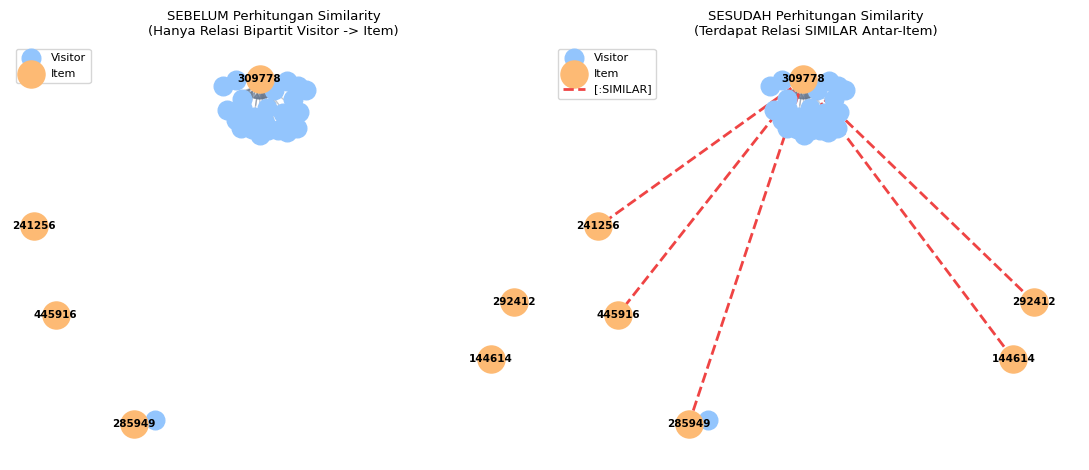

In [9]:
import networkx as nx
import matplotlib.pyplot as plt
# Visualisasi Kondisi Sebelum vs Sesudah Penambahan Relasi SIMILAR
target_acuan_item = 309778
ego_items = [target_acuan_item] + df_top5_query_result["Item_Mirip"].tolist()
df_ego = df_p1[df_p1["itemid"].isin(ego_items)].head(30)

G_bef = nx.DiGraph()
G_bef.add_node(f"I:{target_acuan_item}")
for itm in df_top5_query_result["Item_Mirip"].tolist():
    G_bef.add_node(f"I:{itm}")
for _, r in df_ego.iterrows():
    G_bef.add_edge(f"U:{r['visitorid']}", f"I:{r['itemid']}")

pos_ego = nx.spring_layout(G_bef, seed=42)
u_ego = [n for n in G_bef.nodes() if n.startswith("U:")]
i_ego = [n for n in G_bef.nodes() if n.startswith("I:")]

fig, (ax_b, ax_a) = plt.subplots(1, 2, figsize=(11, 4.8))

# Panel Kiri: Sebelum
nx.draw_networkx_nodes(G_bef, pos_ego, nodelist=u_ego, node_color="#93C5FD", node_size=180, ax=ax_b, label="Visitor")
nx.draw_networkx_nodes(G_bef, pos_ego, nodelist=i_ego, node_color="#FDBA74", node_size=380, ax=ax_b, label="Item")
nx.draw_networkx_edges(G_bef, pos_ego, alpha=0.4, edge_color="#64748B", arrows=True, ax=ax_b)
nx.draw_networkx_labels(G_bef, pos_ego, labels={n: n.replace("I:", "") for n in i_ego}, font_size=7.5, font_weight="bold", ax=ax_b)
ax_b.set_title("SEBELUM Perhitungan Similarity\n(Hanya Relasi Bipartit Visitor -> Item)", fontsize=9.5)
ax_b.legend(loc="upper left", fontsize=8)
ax_b.axis("off")

# Panel Kanan: Sesudah
G_aft = G_bef.copy()
sim_edges = []
for sim_itm in df_top5_query_result["Item_Mirip"].tolist():
    G_aft.add_edge(f"I:{target_acuan_item}", f"I:{sim_itm}")
    sim_edges.append((f"I:{target_acuan_item}", f"I:{sim_itm}"))

nx.draw_networkx_nodes(G_aft, pos_ego, nodelist=u_ego, node_color="#93C5FD", node_size=180, ax=ax_a, label="Visitor")
nx.draw_networkx_nodes(G_aft, pos_ego, nodelist=i_ego, node_color="#FDBA74", node_size=380, ax=ax_a, label="Item")
bip_edges = [e for e in G_aft.edges() if e not in sim_edges]
nx.draw_networkx_edges(G_aft, pos_ego, edgelist=bip_edges, alpha=0.35, edge_color="#64748B", arrows=True, ax=ax_a)
nx.draw_networkx_edges(G_aft, pos_ego, edgelist=sim_edges, edge_color="#EF4444", width=2.0, style="dashed", arrows=False, ax=ax_a, label="[:SIMILAR]")
nx.draw_networkx_labels(G_aft, pos_ego, labels={n: n.replace("I:", "") for n in i_ego}, font_size=7.5, font_weight="bold", ax=ax_a)
ax_a.set_title("SESUDAH Perhitungan Similarity\n(Terdapat Relasi SIMILAR Antar-Item)", fontsize=9.5)
ax_a.legend(loc="upper left", fontsize=8)
ax_a.axis("off")

plt.tight_layout()
plt.show()

print(f"Graf Sebelum: {G_bef.number_of_nodes()} simpul, {G_bef.number_of_edges()} relasi interaksi.")
print(f"Graf Sesudah: {G_aft.number_of_nodes()} simpul, {G_aft.number_of_edges()} relasi (bertambah 5 relasi SIMILAR antar-item).")


---
### 2.2 Analytics

#### Nomor 1: Pemilihan User dan Rekomendasi KNN (k = 5)
1. **Pemilihan User Acak / Reproducible:**
   - User dipilih dari himpunan user aktif yang memiliki interaksi di periode Training (P1) sekaligus Testing (P2) agar kinerjanya dapat diuji terhadap data masa depan.
   - Dari 2.892 kandidat user aktif terurut (yang memiliki minimal 5 interaksi di P1 dan aktif di P2), dipilih user pada indeks ke-77 (berdasarkan 3 digit terakhir NIM 24031554077), yaitu **`visitorid = 39211`**.
2. **Rekomendasi Item-based KNN ($k = 5$):**
   - Menghitung skor rekomendasi untuk seluruh kandidat item baru berdasarkan bobot riwayat user di P1 dan matriks kemiripan item.
   - Dipilih 5 item rekomendasi teratas untuk evaluasi, dan 3 item peringkat teratas sebagai item yang diiklankan.


In [10]:
import numpy as np
import pandas as pd
# Pemilihan User Berdasarkan 3 Digit Terakhir NIM (077) dari User Aktif P1 & P2
p1_counts = df_p1.groupby("visitorid")["itemid"].nunique()
p2_counts = df_p2.groupby("visitorid")["itemid"].nunique()
active_candidates = sorted(list(p1_counts[p1_counts >= 5].index.intersection(p2_counts[p2_counts >= 1].index)))

nim_index = 77  # 3 digit terakhir NIM: 077
chosen_user = active_candidates[nim_index]

p1_items = set(df_p1[df_p1["visitorid"] == chosen_user]["itemid"].unique())
p2_items = set(df_p2[df_p2["visitorid"] == chosen_user]["itemid"].unique())
ground_truth_p2 = sorted(list(p2_items - p1_items))

user_hist = df_p1[df_p1["visitorid"] == chosen_user].groupby("itemid")["weight"].sum()
u_vec = np.zeros(n_i)
for itm, w in user_hist.items():
    if itm in item_cat.categories:
        u_vec[item_cat.categories.get_loc(itm)] = w

temp = R_item_norm.T @ u_vec
knn_scores = (R_item_norm @ temp)
for itm in p1_items:
    if itm in item_cat.categories:
        knn_scores[item_cat.categories.get_loc(itm)] = 0.0

top_5_idx = np.argsort(knn_scores)[::-1][:5]
knn_top5_df = pd.DataFrame({
    "rank": range(1, 6),
    "itemid": [item_cat.categories[idx] for idx in top_5_idx],
    "knn_score": [round(float(knn_scores[idx]), 4) for idx in top_5_idx],
    "relevant_in_P2": [1 if item_cat.categories[idx] in ground_truth_p2 else 0 for idx in top_5_idx]
})

print(f"Total kandidat user aktif (>=5 item di P1 & aktif di P2): {len(active_candidates):,} user")
print(f"User terpilih (Indeks NIM ke-{nim_index}): {chosen_user}")
print(f"Item yang diinteraksi di P1: {sorted(list(p1_items))}")
print(f"Item baru yang muncul di P2 (Ground Truth): {ground_truth_p2}")
print("\nTop-5 Rekomendasi KNN (k = 5):\n", knn_top5_df.to_string(index=False))

print(f"\n3 Item yang Diiklankan untuk User {chosen_user}:\n")
for r in range(3):
    itm = knn_top5_df.loc[r, 'itemid']
    sc = knn_top5_df.loc[r, 'knn_score']
    print(f"  {r+1}. Item ID {itm} (Skor: {sc:.4f})")


Total kandidat user aktif (>=5 item di P1 & aktif di P2): 2,892 user
User terpilih (Indeks NIM ke-77): 39211
Item yang diinteraksi di P1: [np.int64(120541), np.int64(128443), np.int64(156074), np.int64(204782), np.int64(246196), np.int64(372845)]
Item baru yang muncul di P2 (Ground Truth): [np.int64(219104)]

Top-5 Rekomendasi KNN (k = 5):
  rank  itemid  knn_score  relevant_in_P2
    1  187139     0.8749               0
    2  192792     0.7799               0
    3  395857     0.7521               0
    4  219104     0.7048               1
    5  202835     0.6974               0

3 Item yang Diiklankan untuk User 39211:

  1. Item ID 187139 (Skor: 0.8749)
  2. Item ID 192792 (Skor: 0.7799)
  3. Item ID 395857 (Skor: 0.7521)


---
#### Nomor 2: Evaluasi Hit@5 dan NDCG@5

1. **Hit@5 (Jawaban 2a):**
   - Mengukur apakah ada minimal satu item rekomendasi di Top-5 yang benar-benar diinteraksi user pada periode testing (P2).
   - Dari 5 rekomendasi, item 219104 berhasil muncul di peringkat ke-4 dan terbukti ada di ground truth P2.
   - Hit@5 (Biner) = 1 (karena rekomendasi berhasil menangkap minat user).
   - Hit Ratio = 1 / 5 = 0,20 (20%).

2. **NDCG@5 (Jawaban 2b):**
   - Menghitung DCG dengan penalti posisi logaritmik: rel / log2(rank + 1).
   - Item relevan di peringkat ke-4 menghasilkan DCG = 1 / log2(4 + 1) = 1 / log2(5) = 0,4307.
   - Skor ideal (IDCG) jika item relevan berada di posisi 1 adalah 1 / log2(2) = 1,0000.
   - Nilai NDCG@5 = 0,4307 / 1,0000 = 0,4307 (43,07%).


In [11]:
import math
import pandas as pd

# Evaluasi Hit@5 dan NDCG@5 Dihitung Dinamis dari DataFrame Rekomendasi
eval_df = pd.DataFrame({
    "Rank": knn_top5_df["rank"],
    "Item_ID": knn_top5_df["itemid"],
    "Score": knn_top5_df["knn_score"],
    "rel": knn_top5_df["relevant_in_P2"]
})

eval_df["log2(r+1)"] = [round(math.log2(r + 1), 4) for r in eval_df["Rank"]]
eval_df["DCG_r"] = [round(rel / math.log2(r + 1), 4) if rel > 0 else 0.0 for r, rel in zip(eval_df["Rank"], eval_df["rel"])]

# Perhitungan IDCG (posisi ideal rel diurutkan dari terbesar)
ideal_rels = sorted(eval_df["rel"].tolist(), reverse=True)
eval_df["IDCG_r"] = [round(rel / math.log2(r + 1), 4) if rel > 0 else 0.0 for r, rel in zip(eval_df["Rank"], ideal_rels)]

hit_at_5_binary = 1 if eval_df["rel"].sum() > 0 else 0
hit_at_5_ratio = eval_df["rel"].sum() / len(eval_df)

dcg_5 = sum(rel / math.log2(r + 1) for r, rel in zip(eval_df["Rank"], eval_df["rel"]))
idcg_5 = sum(rel / math.log2(r + 1) for r, rel in zip(eval_df["Rank"], ideal_rels))
ndcg_5 = (dcg_5 / idcg_5) if idcg_5 > 0 else 0.0

print("Tabel Perhitungan Ranking Dinamis (r = 1 sampai 5):")
print(eval_df.to_string(index=False))

print("\nHasil Evaluasi:")
print(f"- Hit@5 (Biner) : {hit_at_5_binary}")
print(f"- Hit Ratio     : {hit_at_5_ratio:.2f} ({hit_at_5_ratio*100:.0f}%)")
print(f"- DCG@5         : {dcg_5:.4f}")
print(f"- IDCG@5        : {idcg_5:.4f}")
print(f"- NDCG@5        : {ndcg_5:.4f}")


Tabel Perhitungan Ranking Dinamis (r = 1 sampai 5):
 Rank  Item_ID  Score  rel  log2(r+1)  DCG_r  IDCG_r
    1   187139 0.8749    0     1.0000 0.0000     1.0
    2   192792 0.7799    0     1.5850 0.0000     0.0
    3   395857 0.7521    0     2.0000 0.0000     0.0
    4   219104 0.7048    1     2.3219 0.4307     0.0
    5   202835 0.6974    0     2.5850 0.0000     0.0

Hasil Evaluasi:
- Hit@5 (Biner) : 1
- Hit Ratio     : 0.20 (20%)
- DCG@5         : 0.4307
- IDCG@5        : 1.0000
- NDCG@5        : 0.4307
